In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
X, y = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=1.2,
    random_state=42
)

print("Dataset shape: ",X.shape)
print("\nFirst 5 data points: ",np.round(X[:5],2))

Dataset shape:  (300, 2)

First 5 data points:  [[-7.43 -7.9 ]
 [-7.91 -7.34]
 [-1.52  7.55]
 [ 4.38  3.29]
 [-9.33 -8.09]]


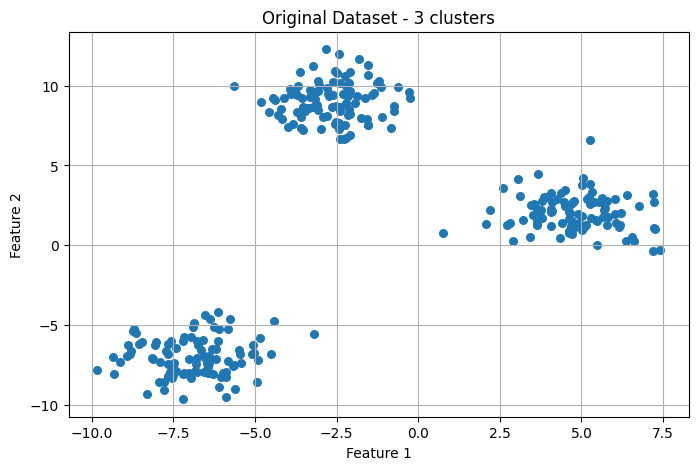

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(X[:, 0], X[:, 1], s=30)

plt.title("Original Dataset - 3 clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.grid(True)
plt.show()

In [8]:
#create the Gaussian Mixture model
gmm = GaussianMixture(
    n_components=3,
    random_state=42
)

#Train the model and prdict the cluster labels
gmm_labels = gmm.fit_predict(X)

print("Unique cluster labels: ",np.unique(gmm_labels))
print("Model converged: ",gmm.converged_)
print("Number of iterations: ",gmm.n_iter_)


Unique cluster labels:  [0 1 2]
Model converged:  True
Number of iterations:  2


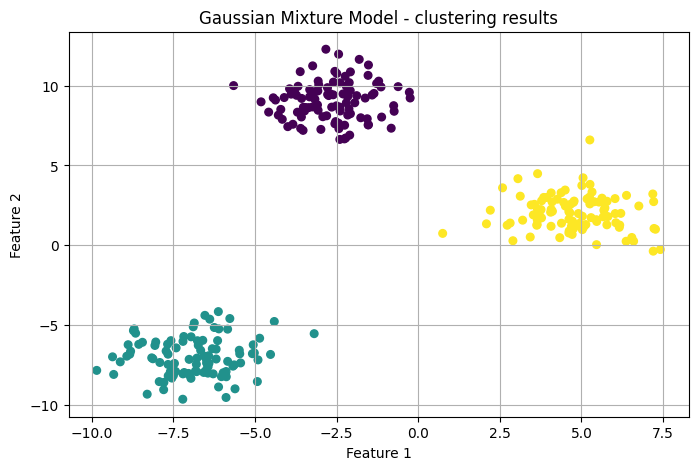

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=gmm_labels,
    cmap='viridis',
    s=30
)

plt.title("Gaussian Mixture Model - clustering results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.grid(True)
plt.show()

In [14]:
probabilities = gmm.predict_proba(X)

print("Probability array shape: ",probabilities.shape)

print("\nProbabilities for first 5 data points: ",np.round(probabilities[:5],2))

print("\nSum of probabilities for first data point: ",round(probabilities[0].sum(),3))

Probability array shape:  (300, 3)

Probabilities for first 5 data points:  [[0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]

Sum of probabilities for first data point:  1.0


In [18]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_label = kmeans.fit_predict(X)

#compare cluster assignments

print("GMM cluster counts: ")
for cluster in np.unique(gmm_labels):
  print(f"Cluster{cluster} : {np.sum(gmm_labels == cluster)} points")

print("\nK-Means cluster counts: ")
for cluster in np.unique(kmeans_label):
  print(f"Cluster{cluster} : {np.sum(kmeans_label == cluster)} points")


GMM cluster counts: 
Cluster0 : 100 points
Cluster1 : 100 points
Cluster2 : 100 points

K-Means cluster counts: 
Cluster0 : 100 points
Cluster1 : 100 points
Cluster2 : 100 points


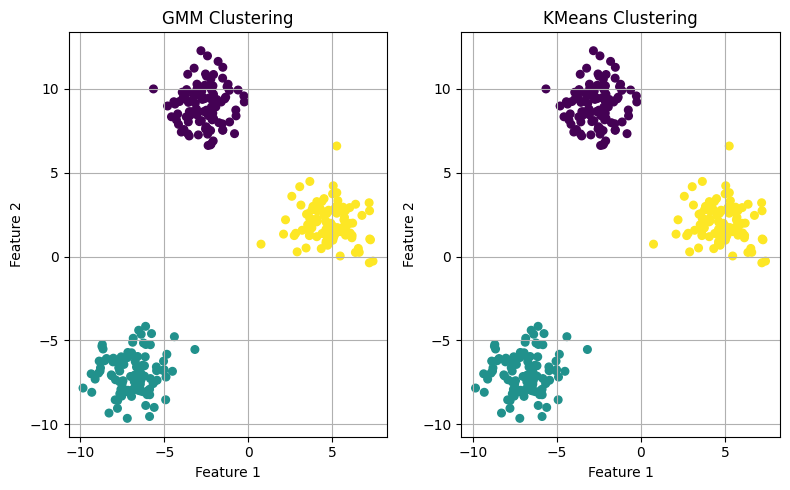

In [20]:
plt.figure(figsize=(8, 5))

#GMM results
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=gmm_labels, cmap='viridis', s=30)
plt.title("GMM Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)

#KMeans results
plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_label, cmap='viridis', s=30)
plt.title("KMeans Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)

plt.tight_layout()
plt.show()

In [23]:
print("GMM component means: ",np.round(gmm.means_, 2))

print("\nGMMM component covariance matrices: ")
for i, covariance in enumerate(gmm.covariances_):
  print(f"\nComponent {i}: ")
  print(np.round(covariance, 2))

print("\nComponent weights: ",np.round(gmm.weights_, 3))

GMM component means:  [[-2.66  9.05]
 [-6.88 -7.  ]
 [ 4.77  2.02]]

GMMM component covariance matrices: 

Component 0: 
[[1.08 0.06]
 [0.06 1.42]]

Component 1: 
[[1.48 0.14]
 [0.14 1.42]]

Component 2: 
[[ 1.54 -0.14]
 [-0.14  1.22]]

Component weights:  [0.333 0.333 0.333]
